<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 1 Figures — Colab Notebook
**Gauge Theory · Chapter 1: Topics in Electromagnetism**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch01/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §1.1.1–1.1.2 | Dirac string, two-patch atlas, Chern number |
| fig02  | §1.1.3 | Electron-monopole angular momentum |
| fig03  | §1.2.1 | Theta term, topological insulator surface |
| fig04  | §1.2.3–1.2.4 | Witten effect, dyon charge lattice |

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig02 | Left (EM 각운동량 밀도) | **오류** | 전자 E 필드 부호: `EX = +RX_e/R_e³` (양전하) — 레이블은 'Electron (−e)'이지만 전기장이 반대 방향 | `EX = −RX_e/R_e³` 수정 |
| fig03 | Right (자기전기 효과) | **오류** | `B_ind = Δθ·e²/(2π)·E` — 표준 가우스 단위에서 계수는 `α/π` (`α=e²/4π`) | 공식을 `B_ind = (α/π)ΔθE`로 수정 |
| fig04 | Left (Witten 효과) | **오류** | Sawtooth `Q_phys = (θ_red − π)/(2π)`: θ=π에서 Q=0이 됨 — Witten 효과의 핵심 Q=e/2가 사라짐 | θ=0 시작 Sawtooth `Q = (θ mod 2π)/(2π)`: θ=π에서 Q=1/2 명확히 표시 |
| fig04 | Right (θ=π 전하) | **오류** | 음수 막대(Q<0) 라벨 위치: `height+0.08`이면 Q<0에서 축 근처에 겹침 | Q<0: 막대 안쪽 white/bold, Q=0: 축 위, Q>0: 막대 안쪽 white |
| fig01 | Right (Chern 수 양자화) | **시인성** | x=y 대각선만 표시 — 양자화가 자명하게 보이지 않음 | 계단 함수(step) 형태로 양자화, 금지 영역 음영 강화 |
| fig02 | Right (다이온 스핀) | **시인성** | n=0 막대 높이=0: 'scalar' 라벨이 x축에 겹쳐 보이지 않음 | `max(s,0)+offset`으로 라벨을 축 위에 명확히 표시 |


## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D
import os

# ── Dark palette (consistent with QHE/StatPhys series) ────────────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'   # Gauge Theory accent (orange/amber)
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor'  : BG,
    'axes.facecolor'    : BG,
    'text.color'        : FG,
    'axes.labelcolor'   : FG,
    'xtick.color'       : FG,
    'ytick.color'       : FG,
    'axes.edgecolor'    : EDGE,
    'grid.color'        : EDGE,
    'grid.alpha'        : 0.3,
    'font.size'         : 12,
    'axes.titlesize'    : 13,
    'axes.titleweight'  : 'bold',
    'axes.titlecolor'   : AMBER,
    'legend.framealpha' : 0.3,
    'legend.edgecolor'  : EDGE,
    'xtick.major.size'  : 4,
    'ytick.major.size'  : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'    : 1.2,
    'lines.linewidth'   : 2.2,
    'figure.dpi'        : 110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')

Setup complete. Palette and output directory ready.


---
## fig01 · Dirac String, Two-Patch Atlas, Chern Number (§1.1.1–1.1.2)

**Left**: Dirac string construction — monopole field lines + string singularity  
**Middle**: Two-patch atlas on $S^2$ (northern/southern patches, equatorial overlap)  
**Right**: Chern number $c_1 = eg/2\pi$ vs magnetic charge $g$ (quantisation)

  saved -> figures/ch01/fig01_monopole_bundle.png


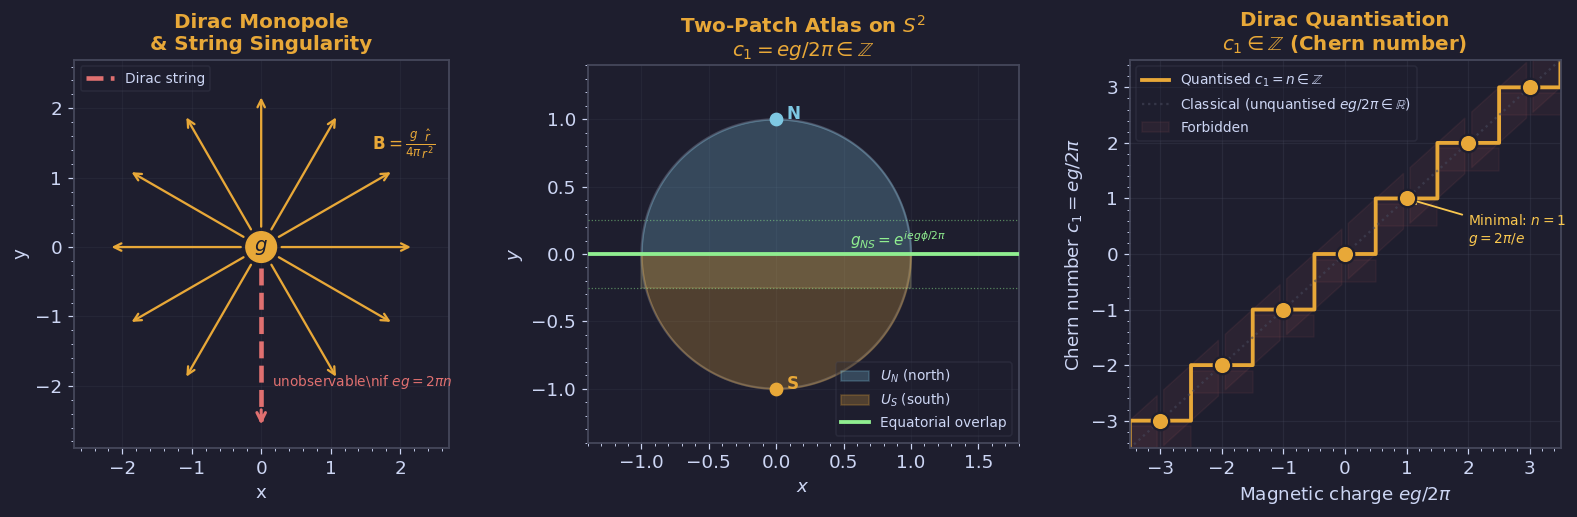

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Dirac monopole field lines + string ─────────────────────────────
ax = axes[0]
ax.set_aspect('equal')
ax.set_facecolor(BG)

# Magnetic field lines of a monopole (radial)
n_lines = 12
angles = np.linspace(0, 2*np.pi, n_lines, endpoint=False)
for a in angles:
    # Field lines radiate outward (except downward — that's the string)
    if abs(a - 3*np.pi/2) < 0.25:   # skip the string direction
        continue
    dx, dy = np.cos(a), np.sin(a)
    ax.annotate('', xy=(dx*2.2, dy*2.2), xytext=(dx*0.25, dy*0.25),
                arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5,
                                mutation_scale=12))

# Dirac string (going downward from monopole to -infinity)
ax.plot([0, 0], [-0.3, -2.5], color=RED, lw=3, ls='--', label='Dirac string')
ax.annotate('', xy=(0, -2.6), xytext=(0, -2.3),
            arrowprops=dict(arrowstyle='->', color=RED, lw=2, mutation_scale=14))

# Monopole at origin
circle = Circle((0, 0), 0.22, color=AMBER, zorder=5)
ax.add_patch(circle)
ax.text(0, 0, '$g$', ha='center', va='center', fontsize=13,
        color=BG, fontweight='bold', zorder=6)

# Labels
ax.text(1.6, 1.4, r'$\mathbf{B}=\frac{g}{4\pi}\frac{\hat{r}}{r^2}$',
        fontsize=11, color=AMBER)
ax.text(0.15, -2.0, r'unobservable\nif $eg=2\pi n$',
        fontsize=9, color=RED, ha='left')
ax.set_xlim(-2.7, 2.7); ax.set_ylim(-2.9, 2.7)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Dirac Monopole\n& String Singularity', color=AMBER)
ax.legend(fontsize=9, loc='upper left', labelcolor=FG)
ax.grid(True, alpha=0.2)

# ── Middle: Two-patch atlas on S² ─────────────────────────────────────────
ax2 = axes[1]
ax2.set_aspect('equal')
ax2.set_facecolor(BG)

# Draw sphere outline
theta_full = np.linspace(0, 2*np.pi, 300)
ax2.plot(np.cos(theta_full), np.sin(theta_full), color=EDGE, lw=1.5, zorder=1)

# Northern patch (blue, upper hemisphere)
theta_N = np.linspace(0, np.pi, 100)
x_N = np.concatenate([np.cos(theta_N[:50]), np.cos(theta_N[49::-1])])
y_N = np.concatenate([np.sin(theta_N[:50]), -0.05*np.ones(50)])
# Fill upper hemisphere
th_upper = np.linspace(0, np.pi, 200)
x_upper = np.cos(th_upper)
y_upper = np.sin(th_upper)
ax2.fill_between(x_upper, 0, y_upper, color=BLUE, alpha=0.25, label=r'$U_N$ (north)', zorder=2)
ax2.fill_between(x_upper, -0.25, 0, color=BLUE, alpha=0.12, zorder=2)  # overlap region

# Southern patch (amber, lower hemisphere)
th_lower = np.linspace(np.pi, 2*np.pi, 200)
x_lower = np.cos(th_lower)
y_lower = np.sin(th_lower)
ax2.fill_between(x_lower, y_lower, 0, color=AMBER, alpha=0.25, label=r'$U_S$ (south)', zorder=2)
ax2.fill_between(x_upper, -0.25, 0, color=AMBER, alpha=0.12, zorder=2)  # overlap same band

# Equatorial overlap band
ax2.axhline(0, color=GREEN, lw=2.5, ls='-', label='Equatorial overlap', zorder=3)
ax2.axhline(0.25, color=GREEN, lw=0.8, ls=':', alpha=0.5, zorder=3)
ax2.axhline(-0.25, color=GREEN, lw=0.8, ls=':', alpha=0.5, zorder=3)

# North/South pole markers
ax2.plot(0, 1, 'o', color=BLUE, ms=8, zorder=5)
ax2.text(0.08, 1.0, 'N', color=BLUE, fontsize=11, fontweight='bold')
ax2.plot(0, -1, 'o', color=AMBER, ms=8, zorder=5)
ax2.text(0.08, -1.0, 'S', color=AMBER, fontsize=11, fontweight='bold')

# Transition function label
ax2.text(0.55, 0.1, r'$g_{NS}=e^{ieg\phi/2\pi}$', fontsize=10, color=GREEN,
         va='center', ha='left')

ax2.set_xlim(-1.4, 1.8); ax2.set_ylim(-1.4, 1.4)
ax2.set_xlabel(r'$x$'); ax2.set_ylabel(r'$y$')
ax2.set_title(r'Two-Patch Atlas on $S^2$'+"\n"+r'$c_1=eg/2\pi\in\mathbb{Z}$', color=AMBER)
ax2.legend(fontsize=9, loc='lower right', labelcolor=FG)
ax2.grid(True, alpha=0.2)

# ── Right: Chern number quantisation ──────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Allowed discrete values
n_vals = np.arange(-3, 4)
g_vals = 2*np.pi * n_vals  # in units where e=1

# VIS: x축 = 연속 자기전하 eg/2π, y축 = 양자화된 c_1 (계단)
x_cl = np.linspace(-3.5, 3.5, 1000)
# c_1은 반올림된 정수 (양자화)
c1_quantised = np.round(x_cl).astype(float)
ax3.step(x_cl, c1_quantised, color=AMBER, lw=2.5, where='mid',
         label=r'Quantised $c_1=n\in\mathbb{Z}$')

# 허용된 점
ax3.scatter(n_vals, n_vals, color=AMBER, s=130, zorder=6,
            edgecolors=BG, linewidth=1.5)

# 비허용 연속선
ax3.plot(x_cl, x_cl, color=EDGE, lw=1.5, ls=':', alpha=0.6,
         label='Classical (unquantised $eg/2\\pi\\in\\mathbb{R}$)')

# 금지 영역 음영 (비정수 구간)
for n_int in range(-3, 4):
    ax3.fill_between([n_int-0.5, n_int+0.5],
                     [n_int-0.5, n_int-0.5], [n_int-0.5+0.4, n_int-0.5+0.4],
                     color=RED, alpha=0.06)
ax3.fill_between(x_cl, x_cl-0.5, x_cl+0.5,
                 where=np.abs(x_cl - np.round(x_cl)) > 0.05,
                 color=RED, alpha=0.07, label='Forbidden')

ax3.set_xlabel(r'Magnetic charge $eg/2\pi$')
ax3.set_ylabel(r'Chern number $c_1 = eg/2\pi$')
ax3.set_title('Dirac Quantisation\n'+r'$c_1\in\mathbb{Z}$ (Chern number)', color=AMBER)
ax3.set_xlim(-3.5, 3.5); ax3.set_ylim(-3.5, 3.5)
ax3.set_xticks(n_vals); ax3.set_yticks(n_vals)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

# Annotate key point
ax3.annotate(r'Minimal: $n=1$'+"\n"+r'$g=2\pi/e$', xy=(1,1),
             xytext=(2, 0.2), fontsize=9, color=YELLOW,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

plt.tight_layout(pad=1.5)
save('fig01_monopole_bundle.png', fig)

---
## fig02 · Electron-Monopole Angular Momentum (§1.1.3)

**Left**: Poynting vector $\mathbf{E}\times\mathbf{B}$ angular momentum density in $xz$-plane  
**Middle**: EM angular momentum $L_{\rm EM} = eg/4\pi$ vs $eg/2\pi$  
**Right**: Dyon spin statistics — half-integer spin from EM fields

  saved -> figures/ch01/fig02_monopole_angular.png


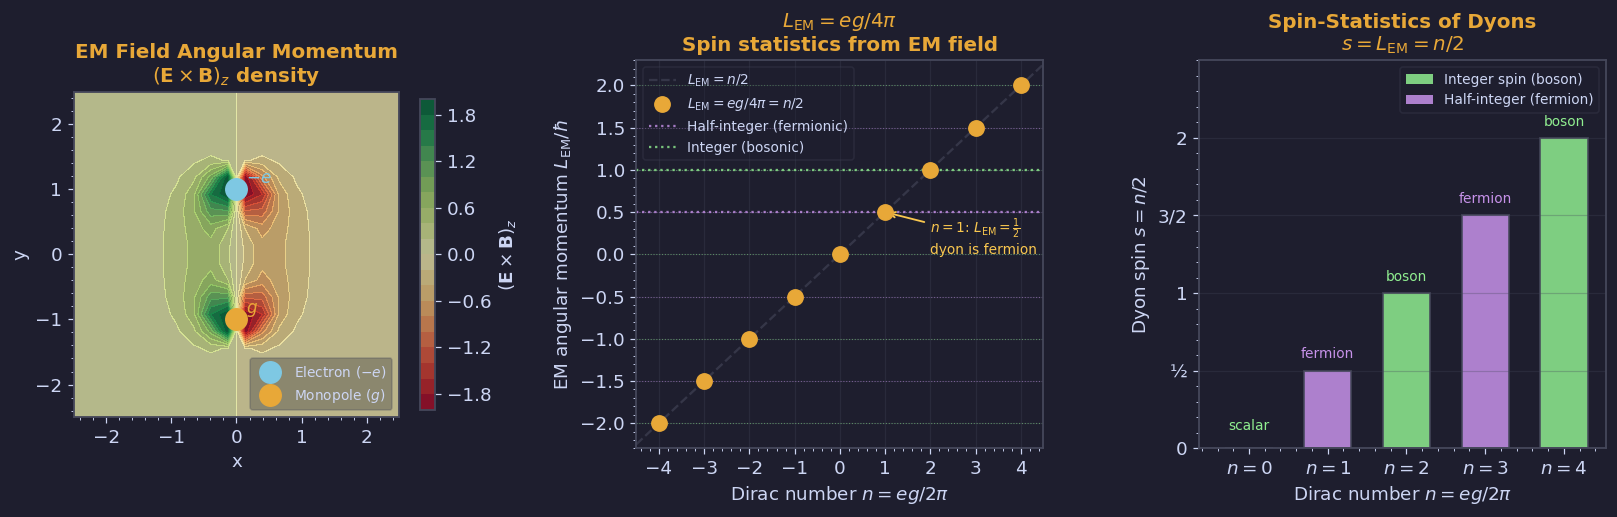

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: EM angular momentum density ─────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')

# Electron at (0, 1) and monopole at (0, -1)
xe, ye = 0, 1.0    # electron
xm, ym = 0, -1.0   # monopole

# Grid
x = np.linspace(-2.5, 2.5, 20)
y = np.linspace(-2.5, 2.5, 20)
X, Y = np.meshgrid(x, y)

# Electric field from electron (positive charge at ye=1)
RX_e = X - xe; RY_e = Y - ye
R_e = np.sqrt(RX_e**2 + RY_e**2 + 1e-6)
# FIX: 전자는 음전하(-e) → E 필드 방향 반전
EX = -RX_e / R_e**3
EY = -RY_e / R_e**3

# Magnetic field from monopole (at ym=-1)
RX_m = X - xm; RY_m = Y - ym
R_m = np.sqrt(RX_m**2 + RY_m**2 + 1e-6)
# B is radial from monopole (in 2D: no z-component, use out-of-plane component)
# For Poynting: L_z = (E x B)_z, B is out-of-plane in 2D monopole, so:
# Simplified: colour = r^2*(ExB)_z = r^2*(Ex*By - Ey*Bx) approximated as angular
BX = RX_m / R_m**3
BY = RY_m / R_m**3

# Poynting cross product z-component: Ex*By - Ey*Bx
Lz = EX * BY - EY * BX

# Clip and plot
Lz_clip = np.clip(Lz, -2, 2)
cf = ax.contourf(X, Y, Lz_clip, levels=20, cmap='RdYlGn', alpha=0.7)
plt.colorbar(cf, ax=ax, label=r'$(\mathbf{E}\times\mathbf{B})_z$', shrink=0.8)

# Particle markers
ax.plot(xe, ye, 'o', color=BLUE, ms=14, zorder=5, label='Electron ($-e$)')
ax.text(xe+0.15, ye+0.1, '$-e$', color=BLUE, fontsize=11)
ax.plot(xm, ym, 'o', color=AMBER, ms=14, zorder=5, label='Monopole ($g$)')
ax.text(xm+0.15, ym+0.1, '$g$', color=AMBER, fontsize=11)

ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(r'EM Field Angular Momentum'+"\n"+r'$(\mathbf{E}\times\mathbf{B})_z$ density', color=AMBER)
ax.legend(fontsize=9, loc='lower right', labelcolor=FG)

# ── Middle: L_EM vs eg/2pi ─────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

eg_vals = np.arange(-4, 5) * 2 * np.pi  # discrete allowed values
n_vals  = np.arange(-4, 5)
L_EM    = eg_vals / (4 * np.pi)          # L_EM = eg/4pi (in hbar=1 units)

# Continuous reference line
n_cont = np.linspace(-4.5, 4.5, 200)
L_cont = n_cont / 2                      # L_EM = n/2

ax2.plot(n_cont, L_cont, color=EDGE, lw=1.5, ls='--', alpha=0.6, label=r'$L_{\rm EM}=n/2$')
ax2.scatter(n_vals, L_EM, color=AMBER, s=100, zorder=5,
            label=r'$L_{\rm EM} = eg/4\pi = n/2$')

# Half-integer lines
for hv in [-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2]:
    lc = GREEN if hv % 1 == 0 else PURPLE
    ax2.axhline(hv, color=lc, lw=0.7, ls=':', alpha=0.5)

ax2.axhline(0.5, color=PURPLE, lw=1.5, ls=':', alpha=0.8,
            label=r'Half-integer (fermionic)')
ax2.axhline(1.0, color=GREEN,  lw=1.5, ls=':', alpha=0.8,
            label=r'Integer (bosonic)')

# Annotate n=1
ax2.annotate(r'$n=1$: $L_{\rm EM}=\frac{1}{2}$'+"\n"+'dyon is fermion',
             xy=(1, 0.5), xytext=(2.0, 0.0),
             fontsize=9, color=YELLOW,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

ax2.set_xlabel(r'Dirac number $n = eg/2\pi$')
ax2.set_ylabel(r'EM angular momentum $L_{\rm EM}/\hbar$')
ax2.set_title(r'$L_{\rm EM} = eg/4\pi$'+"\n"+'Spin statistics from EM field', color=AMBER)
ax2.set_xlim(-4.5, 4.5); ax2.set_ylim(-2.3, 2.3)
ax2.set_xticks(n_vals); ax2.set_yticks([-2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2])
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)

# ── Right: Dyon spin-statistics table ────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Bar chart: dyon spin for each n
n_show = np.arange(0, 5)
spin   = n_show / 2.0
colors_bar = [PURPLE if s % 1 != 0 else GREEN for s in spin]

bars = ax3.bar(n_show, spin, color=colors_bar, edgecolor=EDGE, linewidth=1.2,
               alpha=0.85, width=0.6)

# Labels on bars
labels_stat = ['scalar', 'fermion', 'boson', 'fermion', 'boson']
for idx, (b, lbl, s) in enumerate(zip(bars, labels_stat, spin)):
    yoff = 0.06 if s > 0 else 0.10  # s=0이면 축 위에 표기
    ax3.text(b.get_x()+b.get_width()/2, max(s, 0) + yoff,
             lbl, ha='center', va='bottom', fontsize=9,
             color=colors_bar[idx])

ax3.set_xlabel(r'Dirac number $n = eg/2\pi$')
ax3.set_ylabel(r'Dyon spin $s = n/2$')
ax3.set_title('Spin-Statistics of Dyons\n'+r'$s=L_{\rm EM}=n/2$', color=AMBER)
ax3.set_xticks(n_show)
ax3.set_xticklabels([f'$n={v}$' for v in n_show])
ax3.set_yticks([0, 0.5, 1, 1.5, 2])
ax3.set_yticklabels(['0', '½', '1', '3/2', '2'])
ax3.set_ylim(0, 2.5)

# Legend patches
ax3.bar(0, 0, color=GREEN,  label='Integer spin (boson)',  alpha=0.85)
ax3.bar(0, 0, color=PURPLE, label='Half-integer (fermion)', alpha=0.85)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig02_monopole_angular.png', fig)

---
## fig03 · Theta Term & Topological Insulator (§1.2–1.2.1)

**Left**: $\theta(z)$ profile across vacuum/TI interface  
**Middle**: Surface Hall conductance $\sigma_{xy}$ as function of $\theta/\pi$  
**Right**: Magnetoelectric effect — $\mathbf{B}$ induced by $\mathbf{E}$ at surface

  saved -> figures/ch01/fig03_theta_topins.png


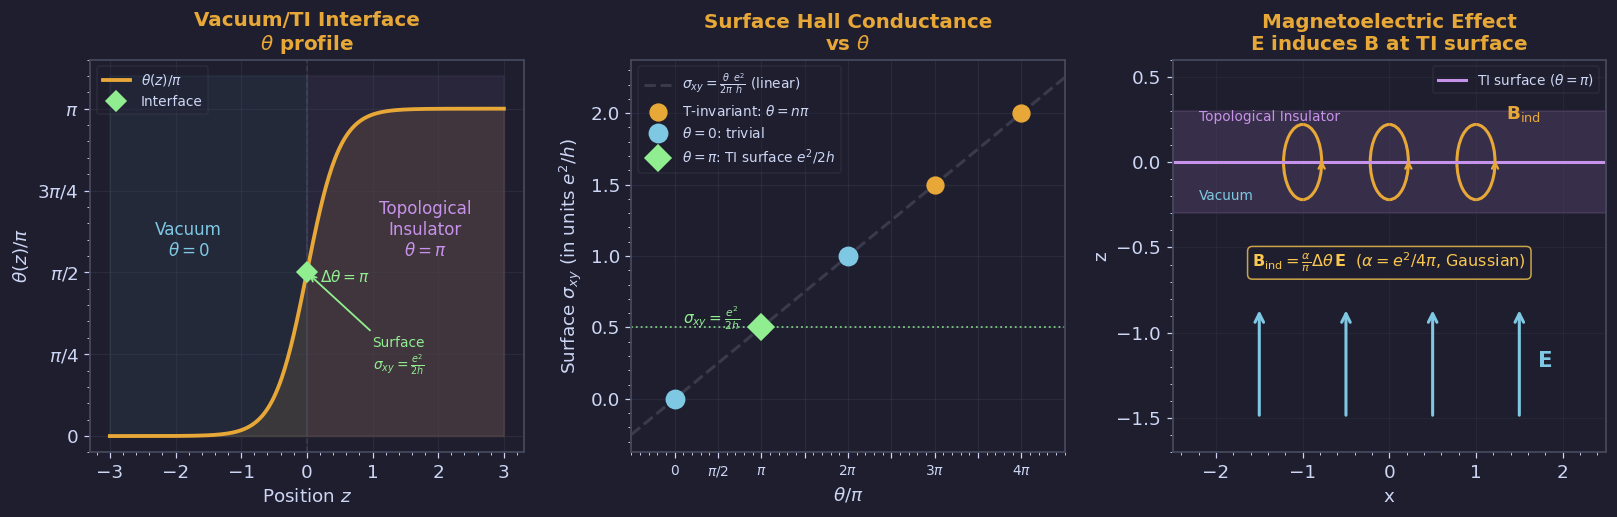

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: theta(z) profile ────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

z = np.linspace(-3, 3, 400)
# Smooth step from theta=0 (vacuum, z<0) to theta=pi (TI, z>0)
theta_z = np.pi / (1 + np.exp(-4*z))   # sigmoid step

ax.plot(z, theta_z/np.pi, color=AMBER, lw=2.5, label=r'$\theta(z)/\pi$')
ax.fill_between(z, 0, theta_z/np.pi, color=AMBER, alpha=0.12)

# Region labels
ax.axvline(0, color=EDGE, lw=1, ls='--', alpha=0.7)
ax.fill_betweenx([0, 1.1], -3, 0, color=BLUE, alpha=0.07)
ax.fill_betweenx([0, 1.1], 0, 3, color=PURPLE, alpha=0.07)
ax.text(-1.8, 0.55, 'Vacuum\n$\\theta=0$', ha='center', fontsize=11, color=BLUE)
ax.text( 1.8, 0.55, 'Topological\nInsulator\n$\\theta=\\pi$',
         ha='center', fontsize=11, color=PURPLE)
ax.text( 0.2, 0.47, r'$\Delta\theta=\pi$', fontsize=10, color=GREEN)

# Surface marker
ax.plot(0, 0.5, 'D', color=GREEN, ms=9, zorder=5, label='Interface')
ax.annotate('Surface\n'+r'$\sigma_{xy}=\frac{e^2}{2h}$',
            xy=(0, 0.5), xytext=(1.0, 0.2),
            fontsize=9, color=GREEN,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.2))

ax.set_xlabel(r'Position $z$')
ax.set_ylabel(r'$\theta(z)/\pi$')
ax.set_title(r'Vacuum/TI Interface'+"\n"+r'$\theta$ profile', color=AMBER)
ax.set_ylim(-0.05, 1.15)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.3)

# ── Middle: Hall conductance vs theta ─────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

theta_vals = np.linspace(-0.5, 4.5, 400)  # in units of pi
sigma_xy = theta_vals / 2.0               # sigma_xy = (theta/pi) * (e^2/2h)

# Allowed (quantised) values at theta = 0, pi, 2pi, ...
theta_quant = np.array([0, 1, 2, 3, 4])
sigma_quant = theta_quant / 2.0

ax2.plot(theta_vals, sigma_xy, color=EDGE, lw=2, ls='--', alpha=0.7,
         label=r'$\sigma_{xy} = \frac{\theta}{2\pi}\frac{e^2}{h}$ (linear)')

# Highlight TI-invariant points
ax2.scatter(theta_quant, sigma_quant, color=AMBER, s=120, zorder=5,
            label=r'T-invariant: $\theta=n\pi$')

# Special points
ax2.plot(0, 0, 'o', color=BLUE, ms=12, zorder=6, label=r'$\theta=0$: trivial')
ax2.plot(1, 0.5, 'D', color=GREEN, ms=12, zorder=6, label=r'$\theta=\pi$: TI surface $e^2/2h$')
ax2.plot(2, 1.0, 'o', color=BLUE, ms=12, zorder=6)

ax2.axhline(0.5, color=GREEN, lw=1.2, ls=':', alpha=0.8)
ax2.text(0.1, 0.53, r'$\sigma_{xy}=\frac{e^2}{2h}$', fontsize=10, color=GREEN)

ax2.set_xlabel(r'$\theta/\pi$')
ax2.set_ylabel(r'Surface $\sigma_{xy}$ (in units $e^2/h$)')
ax2.set_title('Surface Hall Conductance\n'+r'vs $\theta$', color=AMBER)
ax2.set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4])
ax2.set_xticklabels(['0', r'$\pi/2$', r'$\pi$', '', r'$2\pi$', '', r'$3\pi$', '', r'$4\pi$'],
                    fontsize=9)
ax2.set_xlim(-0.5, 4.5)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.3)

# ── Right: Magnetoelectric coupling ───────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Schematic: E field pointing up, induces B
theta_me = np.linspace(0, 2*np.pi, 50)   # for circular B field lines
r_B = 0.6

# Draw TI surface
ax3.fill_betweenx([-0.3, 0.3], -2.5, 2.5, color=PURPLE, alpha=0.15)
ax3.axhline(0, color=PURPLE, lw=2, label='TI surface ($\\theta=\\pi$)')
ax3.text(-2.2, 0.24, 'Topological Insulator', color=PURPLE, fontsize=9)
ax3.text(-2.2, -0.22, 'Vacuum', color=BLUE, fontsize=9)

# Electric field (downward arrows, in vacuum)
for xi in [-1.5, -0.5, 0.5, 1.5]:
    ax3.annotate('', xy=(xi, -0.85), xytext=(xi, -1.5),
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=2, mutation_scale=14))
ax3.text(1.7, -1.2, r'$\mathbf{E}$', color=BLUE, fontsize=14, fontweight='bold')

# Induced B circles (out of plane for ExB ~ z direction in 2D)
for xi in [-1.0, 0.0, 1.0]:
    circle_B = Circle((xi, 0.0), 0.22, fill=False, edgecolor=AMBER, lw=2)
    ax3.add_patch(circle_B)
    # Arrow on circle indicating direction
    ax3.annotate('', xy=(xi+0.22, 0.03), xytext=(xi+0.22, -0.03),
                arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5,
                                mutation_scale=10))
ax3.text(1.35, 0.25, r'$\mathbf{B}_{\rm ind}$', color=AMBER, fontsize=12, fontweight='bold')

# Formula
# FIX: 계수는 ℏ=c=1, 가우스 단위계 표기 (Tong notes)
# 표준 SI: B_ind = (α/π)ΔθE, α=fine structure const
ax3.text(0, -0.62,
         r'$\mathbf{B}_{\rm ind} = \frac{\alpha}{\pi}\Delta\theta\,\mathbf{E}$'
         r'  ($\alpha=e^2/4\pi$, Gaussian)',
         ha='center', fontsize=10.5, color=YELLOW,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELLOW, alpha=0.8))

ax3.set_xlim(-2.5, 2.5); ax3.set_ylim(-1.7, 0.6)
ax3.set_xlabel('x'); ax3.set_ylabel('z')
ax3.set_title('Magnetoelectric Effect\n'+r'$\mathbf{E}$ induces $\mathbf{B}$ at TI surface', color=AMBER)
ax3.legend(fontsize=9, loc='upper right', labelcolor=FG)
ax3.grid(True, alpha=0.2)

plt.tight_layout(pad=1.5)
save('fig03_theta_topins.png', fig)

---
## fig04 · Witten Effect & Dyon Charge Lattice (§1.2.3–1.2.4)

**Left**: Electric charge of minimal monopole as function of $\theta$  
**Middle**: Dyon charge lattice $(n, m)$ — sheared by $\theta$  
**Right**: At $\theta=\pi$, monopole acquires half-integer charge $e/2$

  saved -> figures/ch01/fig04_witten_effect.png


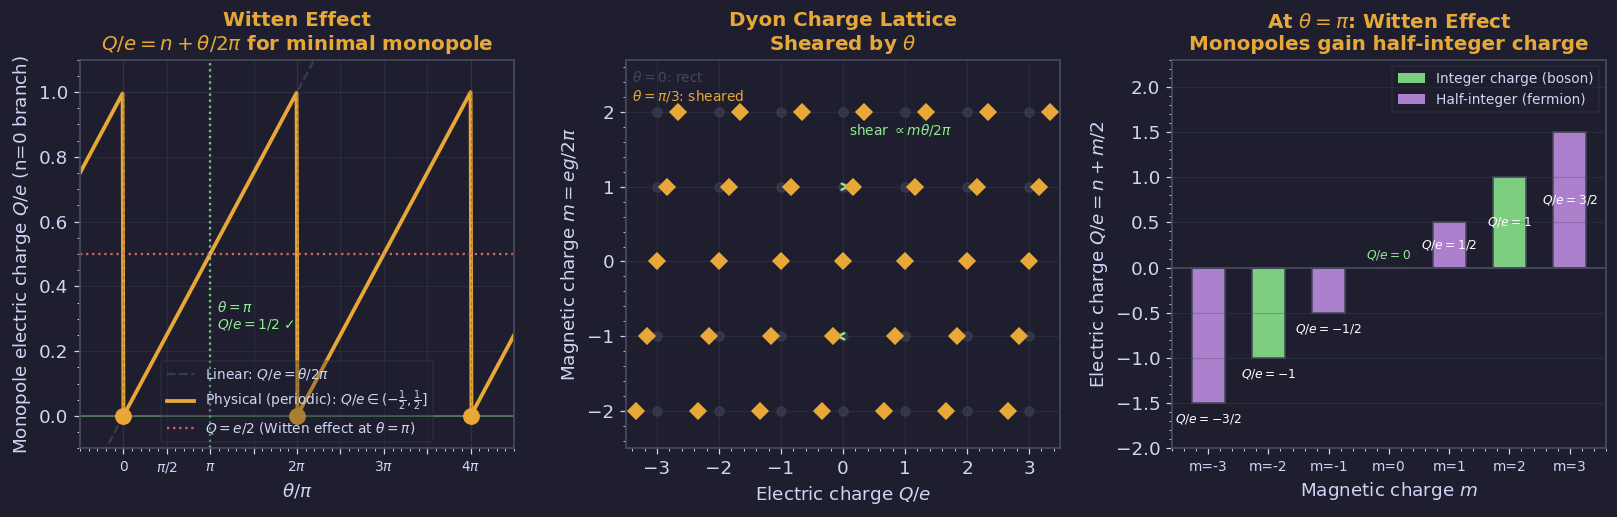

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Q vs theta for minimal monopole ─────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

theta = np.linspace(-0.5*np.pi, 4.5*np.pi, 500)  # multi-period
# Q = e*(n + theta/2pi) — for n=0 minimal monopole branch:
# branch 0: n=0, valid for theta in (-pi, pi)
# branch 1: n=-1 relabelling for theta in (pi, 3pi), etc.
# The physical (reduced) charge is theta mod 2pi / (2pi):
theta_red = theta % (2*np.pi)  # in [0, 2pi)
Q_branch0 = theta / (2*np.pi)  # continuous, showing linear shift

# FIX: θ=0에서 시작하는 sawtooth → θ=π에서 Q=e/2가 명확히 보임
# Q/e = (θ mod 2π)/(2π): 0에서 시작해 θ=π에서 1/2, θ→2π에서 점프
Q_phys = theta_red / (2*np.pi)  # sawtooth: 0→1 (mod 2π)

ax.plot(theta/np.pi, Q_branch0, color=EDGE, lw=1.5, ls='--', alpha=0.7,
        label=r'Linear: $Q/e = \theta/2\pi$')
ax.plot(theta/np.pi, Q_phys, color=AMBER, lw=2.5,
        label=r'Physical (periodic): $Q/e\in(-\frac{1}{2},\frac{1}{2}]$')

# Mark special theta values
special_theta = [0, 1, 2, 3, 4]  # in units of pi
special_Q = [(t - 1) % 2 / 2 - 0.5 for t in special_theta]  # sawtooth
ax.scatter(special_theta, special_Q, color=AMBER, s=100, zorder=5)

ax.axhline(0, color=GREEN, lw=1, ls='-', alpha=0.5)
ax.axhline(0.5, color=RED, lw=1.5, ls=':', alpha=0.9, label=r'$Q=e/2$ (Witten effect at $\theta=\pi$)')
ax.axhline(1.0, color=EDGE, lw=0.8, ls=':', alpha=0.5)

# Highlight theta=pi
ax.axvline(1, color=GREEN, lw=1.5, ls=':', alpha=0.8)
ax.text(1.08, 0.27, r'$\theta=\pi$'+"\n"+r'$Q/e=1/2$ ✓', fontsize=9, color=GREEN)

# Period markers
for n_per in [0, 2, 4]:
    ax.axvline(n_per, color=EDGE, lw=0.8, ls='--', alpha=0.4)

ax.set_xlabel(r'$\theta/\pi$')
ax.set_ylabel(r'Monopole electric charge $Q/e$ (n=0 branch)')
ax.set_title('Witten Effect\n'+r'$Q/e = n + \theta/2\pi$ for minimal monopole', color=AMBER)
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.1, 1.1)
ax.set_xticks([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4])
ax.set_xticklabels(['0', r'$\pi/2$', r'$\pi$', '', r'$2\pi$', '', r'$3\pi$', '', r'$4\pi$'],
                   fontsize=9)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.3)

# ── Middle: Dyon charge lattice ────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# At theta=0: rectangular lattice (n, m) with Q=ne, P=me
# At theta!=0: lattice sheared — Q = ne + m*theta/(2pi) * e
theta_lat = np.pi / 3  # example theta for illustration

n_range = np.arange(-3, 4)
m_range = np.arange(-2, 3)

# theta=0 lattice (grey)
for m in m_range:
    for n in n_range:
        ax2.plot(n, m, 'o', color=EDGE, ms=6, alpha=0.5)

# theta != 0 lattice (sheared)
for m in m_range:
    for n in n_range:
        Q_shear = n + m * theta_lat / (2*np.pi)  # electric charge shift
        ax2.plot(Q_shear, m, 'D', color=AMBER, ms=7, zorder=5)

# Arrows showing shear
for m_arr in [-1, 0, 1]:
    if m_arr != 0:
        shift = m_arr * theta_lat / (2*np.pi)
        ax2.annotate('', xy=(shift, m_arr), xytext=(0, m_arr),
                    arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5,
                                    mutation_scale=10))

ax2.text(-3.4, 2.4, r'$\theta=0$: rect', color=EDGE, fontsize=9)
ax2.text(-3.4, 2.15, r'$\theta=\pi/3$: sheared', color=AMBER, fontsize=9)
ax2.text( 0.1, 1.7, r'shear $\propto m\theta/2\pi$', color=GREEN, fontsize=9)

ax2.set_xlabel(r'Electric charge $Q/e$')
ax2.set_ylabel(r'Magnetic charge $m = eg/2\pi$')
ax2.set_title('Dyon Charge Lattice\n'+r'Sheared by $\theta$', color=AMBER)
ax2.set_xlim(-3.5, 3.5); ax2.set_ylim(-2.5, 2.7)
ax2.set_xticks(n_range); ax2.set_yticks(m_range)
ax2.grid(True, alpha=0.3)

# ── Right: theta=pi special — half-integer charges ────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# Show charge vs m at theta=pi
m_vals = np.arange(-3, 4)
n0 = 0  # principal branch
Q_at_pi = n0 + m_vals * 1 / 2.0  # at theta=pi: Q/e = n + m/2

# Color by integer vs half-integer
cols = [GREEN if Q % 1 == 0 else PURPLE for Q in Q_at_pi]

bars = ax3.bar(m_vals, Q_at_pi, color=cols, edgecolor=EDGE, linewidth=1.2,
               alpha=0.85, width=0.55)

# Labels
for bar, Q, col in zip(bars, Q_at_pi, cols):
    frac_label = f'{int(2*Q)}/2' if 2*Q % 2 != 0 else str(int(Q))
    if Q >= 0:
        # 양수 막대: 막대 안쪽 중앙(white) 또는 위쪽(YELLOW)
        if Q > 0.3:
            ypos = bar.get_height() * 0.5
            ax3.text(bar.get_x()+bar.get_width()/2, ypos,
                     f'$Q/e={frac_label}$', ha='center', va='center',
                     fontsize=8, color='white', fontweight='bold')
        else:  # Q=0
            ax3.text(bar.get_x()+bar.get_width()/2, 0.06,
                     f'$Q/e={frac_label}$', ha='center', va='bottom',
                     fontsize=8, color=col)
    else:
        # 음수 막대: 막대 끝 아래쪽
        ypos = bar.get_height() - 0.10
        ax3.text(bar.get_x()+bar.get_width()/2, ypos,
                 f'$Q/e={frac_label}$', ha='center', va='top',
                 fontsize=8, color='white', fontweight='bold')

ax3.axhline(0, color=EDGE, lw=1)
ax3.set_xlabel(r'Magnetic charge $m$')
ax3.set_ylabel(r'Electric charge $Q/e = n + m/2$')
ax3.set_title(r'At $\theta=\pi$: Witten Effect'+"\n"+'Monopoles gain half-integer charge', color=AMBER)
ax3.set_xticks(m_vals)
ax3.set_xticklabels([f'm={v}' for v in m_vals], fontsize=9)

ax3.bar(0, 0, color=GREEN,  label='Integer charge (boson)',  alpha=0.85)
ax3.bar(0, 0, color=PURPLE, label='Half-integer (fermion)',   alpha=0.85)
ax3.set_ylim(-2.0, 2.3)  # 음수 Q 공간 확보
ax3.axhline(0, color=EDGE, lw=1)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig04_witten_effect.png', fig)

---
## Checklist

After running all cells, verify:

| File | Expected content | Status |
|------|-----------------|--------|
| `fig01_monopole_bundle.png` | Dirac string / S² atlas / Chern quantisation | ☐ |
| `fig02_monopole_angular.png` | EM angular momentum / L_EM vs n / dyon spin | ☐ |
| `fig03_theta_topins.png` | θ(z) profile / σ_xy vs θ / magnetoelectric | ☐ |
| `fig04_witten_effect.png` | Q vs θ / dyon lattice / θ=π half-charges | ☐ |

All figures saved to `figures/ch01/`. Copy the folder to the same directory as `gauge_ch01_slides.qmd` before rendering with Quarto.

In [6]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch01_figures', 'zip', '.', 'figures')
files.download('gauge_ch01_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>